In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_excel("BlinkIT Grocery Data.xlsx")
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [7]:
df.columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type',
       'Outlet Establishment Year', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type', 'Item Visibility',
       'Item Weight', 'Sales', 'Rating'],
      dtype='str')

In [11]:
df["Item Type"].value_counts()

Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

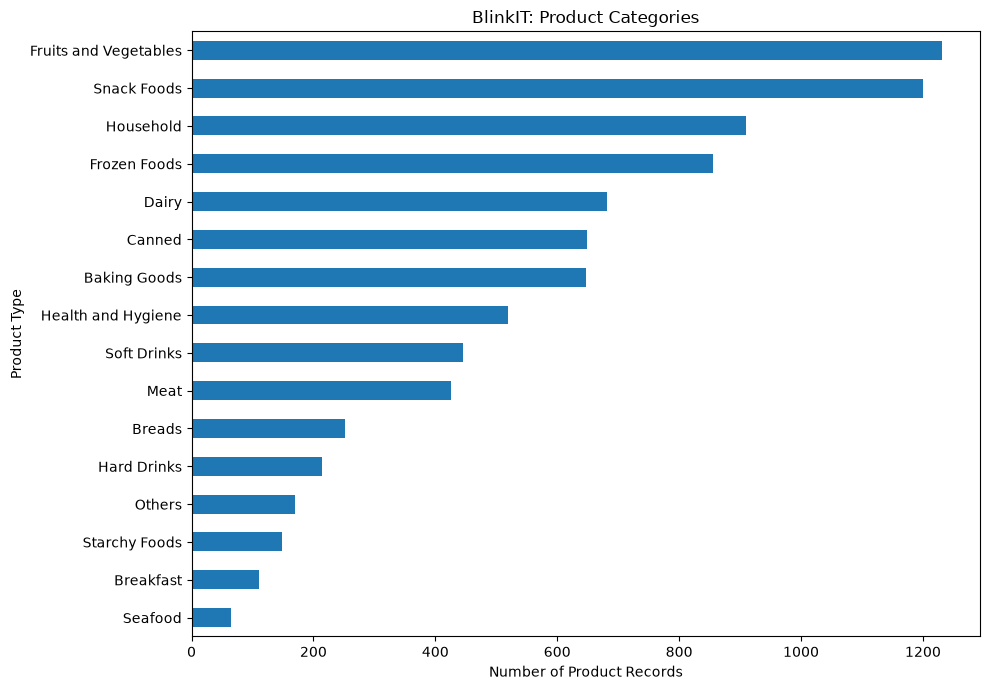

In [12]:
product_counts = df["Item Type"].value_counts().sort_values()

plt.figure(figsize=(10, 7))
product_counts.plot(kind="barh")

plt.title("BlinkIT: Product Categories")
plt.xlabel("Number of Product Records")
plt.ylabel("Product Type")
plt.tight_layout()
plt.show()

In [14]:
outlet_columns = [
    "Outlet Type",
    "Outlet Location Type",
    "Outlet Establishment Year"
]
df[outlet_columns].head()

,Outlet Type,Outlet Location Type,Outlet Establishment Year
0,Supermarket Type1,Tier 1,2012
1,Supermarket Type2,Tier 3,2022
2,Supermarket Type1,Tier 1,2016
3,Supermarket Type1,Tier 3,2014
4,Supermarket Type1,Tier 2,2015


In [15]:
df["Outlet Type"].value_counts()

Outlet Type
Supermarket Type1    5577
Grocery Store        1083
Supermarket Type3     935
Supermarket Type2     928
Name: count, dtype: int64

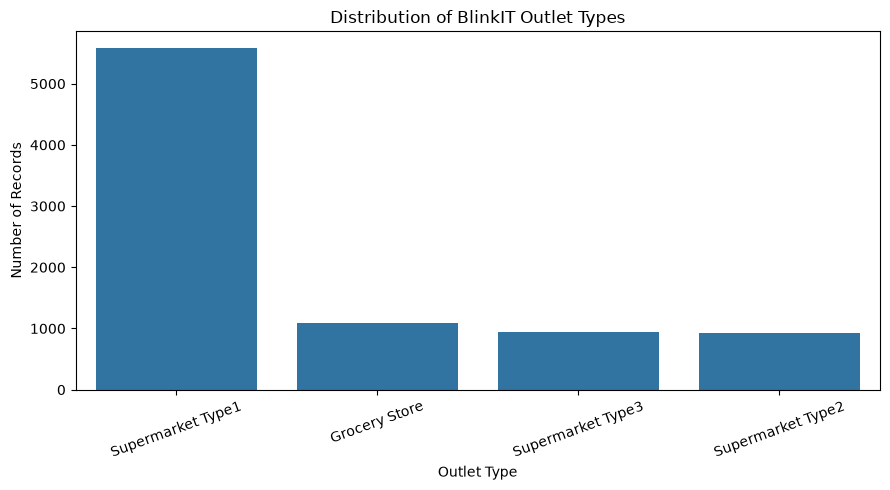

In [16]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Outlet Type",
    order=df["Outlet Type"].value_counts().index
)

plt.title("Distribution of BlinkIT Outlet Types")
plt.xlabel("Outlet Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


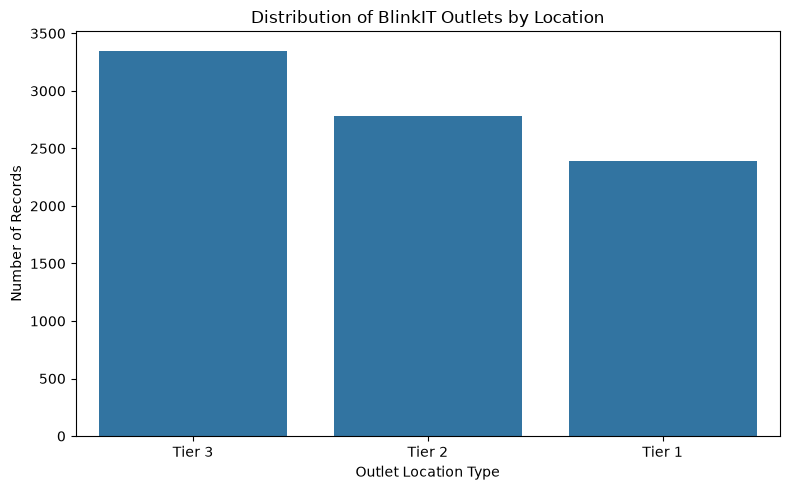

In [17]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="Outlet Location Type",
    order=df["Outlet Location Type"].value_counts().index
)

plt.title("Distribution of BlinkIT Outlets by Location")
plt.xlabel("Outlet Location Type")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()


In [18]:
total_sales = df["Sales"].sum()
average_sales = df["Sales"].mean()
maximum_sales = df["Sales"].max()
minimum_sales = df["Sales"].min()
total_records = len(df)

print("Total Sales: ₹", round(total_sales, 2))
print("Average Sales per Record: ₹", round(average_sales, 2))
print("Maximum Sales per Record: ₹", round(maximum_sales, 2))
print("Minimum Sales per Record: ₹", round(minimum_sales, 2))
print("Total Records:", total_records)

Total Sales: ₹ 1201681.49
Average Sales per Record: ₹ 140.99
Maximum Sales per Record: ₹ 266.89
Minimum Sales per Record: ₹ 31.29
Total Records: 8523


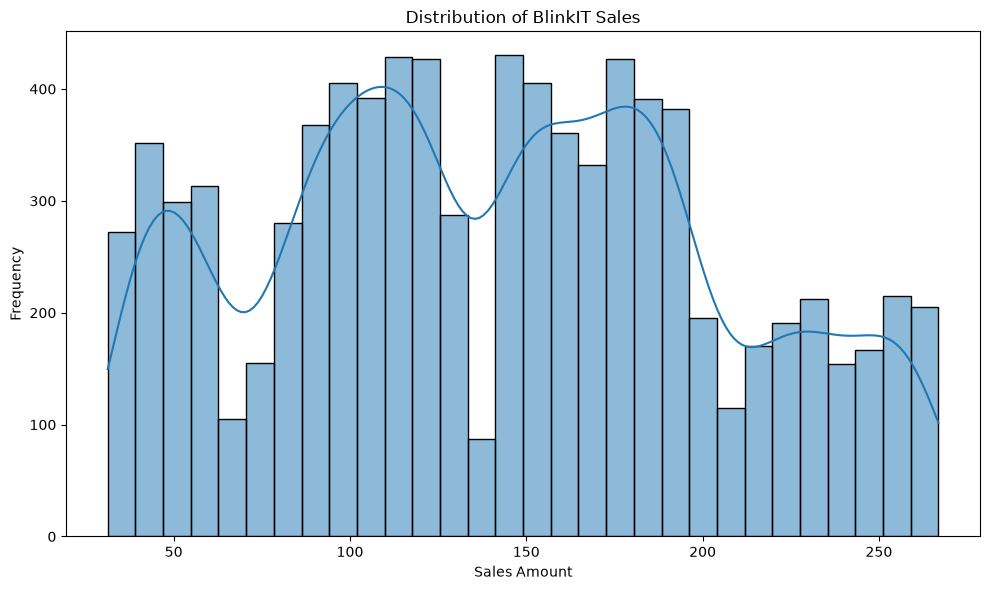

In [19]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="Sales",
    bins=30,
    kde=True
)

plt.title("Distribution of BlinkIT Sales")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [20]:
print("Average Customer Rating:", round(df["Rating"].mean(), 2))
print("Highest Rating:", df["Rating"].max())
print("Lowest Rating:", df["Rating"].min())
print("Missing Ratings:", df["Rating"].isna().sum())

Average Customer Rating: 3.97
Highest Rating: 5.0
Lowest Rating: 1.0
Missing Ratings: 0


Text(0, 0.5, 'Number of Records')

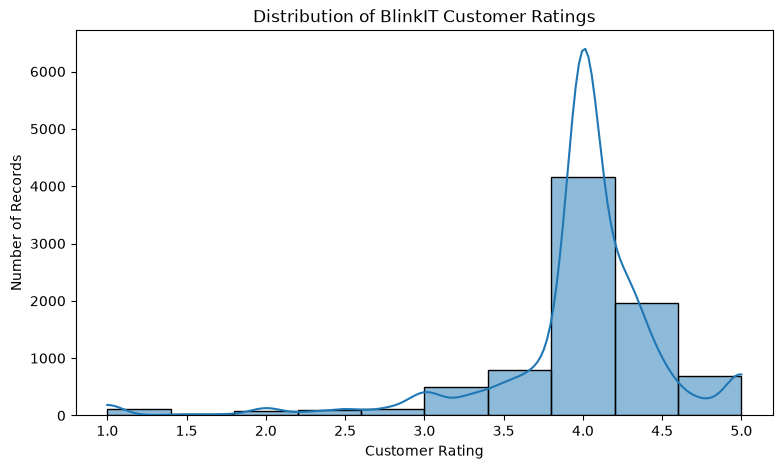

In [21]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="Rating", bins=10, kde=True)

plt.title("Distribution of BlinkIT Customer Ratings")
plt.xlabel("Customer Rating")
plt.ylabel("Number of Records")

In [22]:
product_performance = (
    df.groupby("Item Type")
      .agg(
          Total_Sales=("Sales", "sum"),
          Average_Rating=("Rating", "mean"),
          Product_Records=("Item Identifier", "count")
      )
      .sort_values("Total_Sales", ascending=False)
      .reset_index()
)

display(product_performance.round(2))

,Item Type,Total_Sales,Average_Rating,Product_Records
0,Fruits and Vegetables,178124.08,3.96,1232
1,Snack Foods,175433.92,3.95,1200
2,Household,135976.53,4.00,910
3,Frozen Foods,118558.88,3.97,856
4,Dairy,101276.46,3.97,682
5,Canned,90706.73,3.99,649
6,Baking Goods,81894.74,3.98,648
7,Health and Hygiene,68025.84,3.99,520
8,Meat,59449.86,4.02,425
9,Soft Drinks,58514.17,3.92,445


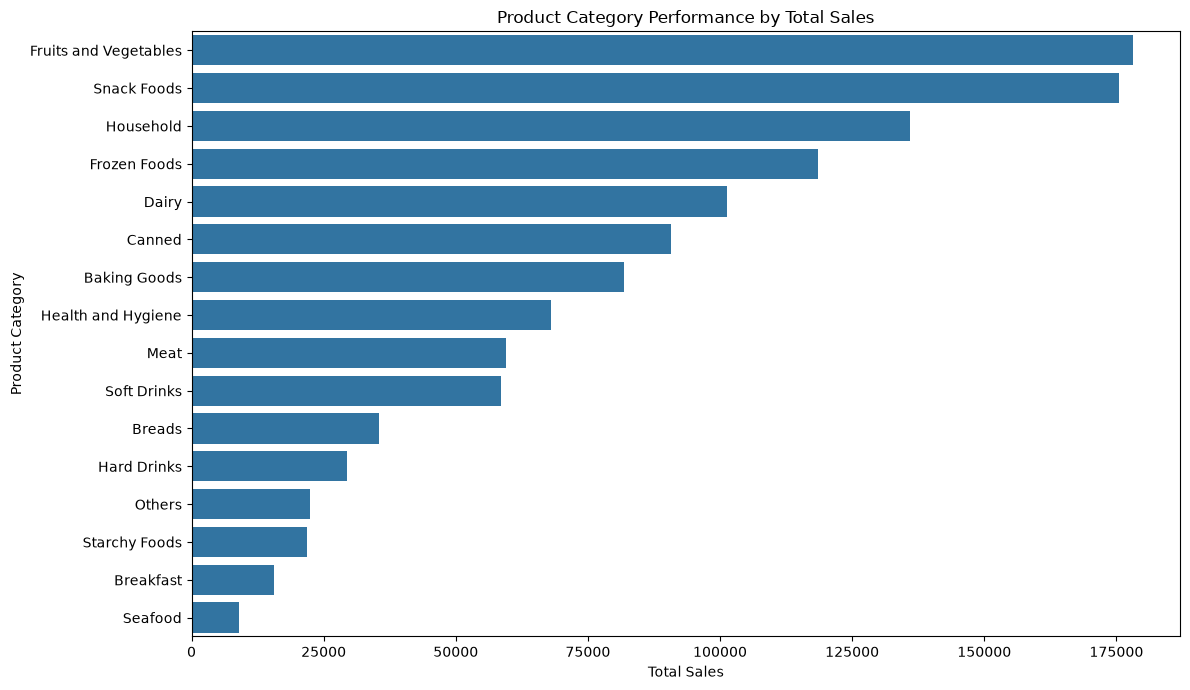

In [23]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=product_performance,
    x="Total_Sales",
    y="Item Type"
)

plt.title("Product Category Performance by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()


In [25]:
missing_values = df.isnull().sum()
print(missing_values)


Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Sales                           0
Rating                          0
dtype: int64


In [26]:
missing_percentage = (missing_values / len(df)) * 100
print(missing_percentage)

Item Fat Content              0.000000
Item Identifier               0.000000
Item Type                     0.000000
Outlet Establishment Year     0.000000
Outlet Identifier             0.000000
Outlet Location Type          0.000000
Outlet Size                   0.000000
Outlet Type                   0.000000
Item Visibility               0.000000
Item Weight                  17.165317
Sales                         0.000000
Rating                        0.000000
dtype: float64


In [29]:
print(df.duplicated().sum())

0


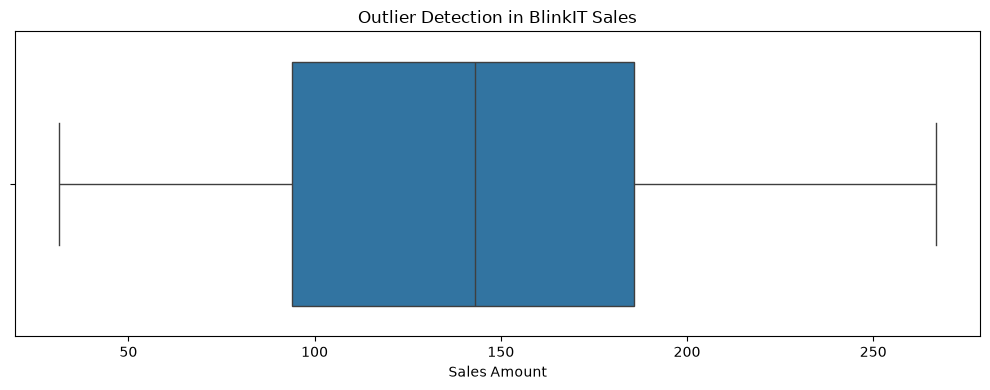

In [31]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["Sales"])

plt.title("Outlier Detection in BlinkIT Sales")
plt.xlabel("Sales Amount")
plt.tight_layout()
plt.show()

In [33]:
df['Item Fat Content'].unique()


<StringArray>
['Regular', 'Low Fat', 'low fat', 'LF', 'reg']
Length: 5, dtype: str

In [34]:
df['Item Fat Content']=df['Item Fat Content'].replace({"LF":"Low Fat","low fat":"Low Fat","reg":"Regular"})

In [36]:
df.head(10)


,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2016,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2014,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0
5,Low Fat,FDS52,Frozen Foods,2020,OUT017,Tier 2,Small,Supermarket Type1,0.005505,8.89,102.4016,5.0
6,Low Fat,NCU05,Health and Hygiene,2011,OUT010,Tier 3,Small,Grocery Store,0.098312,11.80,81.4618,5.0
7,Low Fat,NCD30,Household,2015,OUT045,Tier 2,Small,Supermarket Type1,0.026904,19.70,96.0726,5.0
8,Low Fat,FDW20,Fruits and Vegetables,2014,OUT013,Tier 3,High,Supermarket Type1,0.024129,20.75,124.1730,5.0
9,Low Fat,FDX25,Canned,2018,OUT027,Tier 3,Medium,Supermarket Type3,0.101562,NaN,181.9292,5.0


In [37]:
product_sales = (
    df.groupby("Item Type")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print("Product Categories Ranked by Total Sales:")
display(product_sales)

Product Categories Ranked by Total Sales:


,Item Type,Sales
0,Fruits and Vegetables,178124.0810
1,Snack Foods,175433.9224
2,Household,135976.5254
3,Frozen Foods,118558.8814
4,Dairy,101276.4616
5,Canned,90706.7290
6,Baking Goods,81894.7364
7,Health and Hygiene,68025.8388
8,Meat,59449.8638
9,Soft Drinks,58514.1670


In [38]:
outlet_performance = (
    df.groupby("Outlet Type")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Number_of_Records=("Sales", "count")
    )
    .sort_values("Total_Sales", ascending=False)
    .reset_index()
)

display(outlet_performance.round(2))

,Outlet Type,Total_Sales,Average_Sales,Number_of_Records
0,Supermarket Type1,787549.89,141.21,5577
1,Grocery Store,151939.15,140.29,1083
2,Supermarket Type2,131477.78,141.68,928
3,Supermarket Type3,130714.67,139.80,935


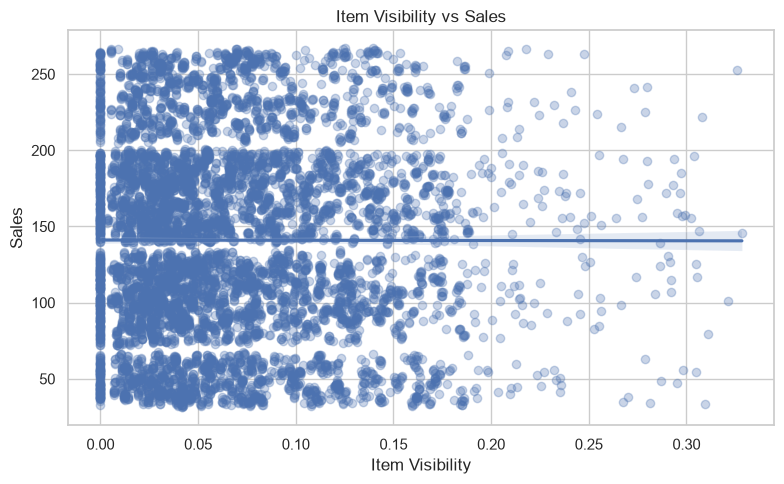

In [43]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="Item Visibility", y="Sales",
            scatter_kws={"alpha": 0.3})
plt.title("Item Visibility vs Sales")
plt.tight_layout()
plt.show()

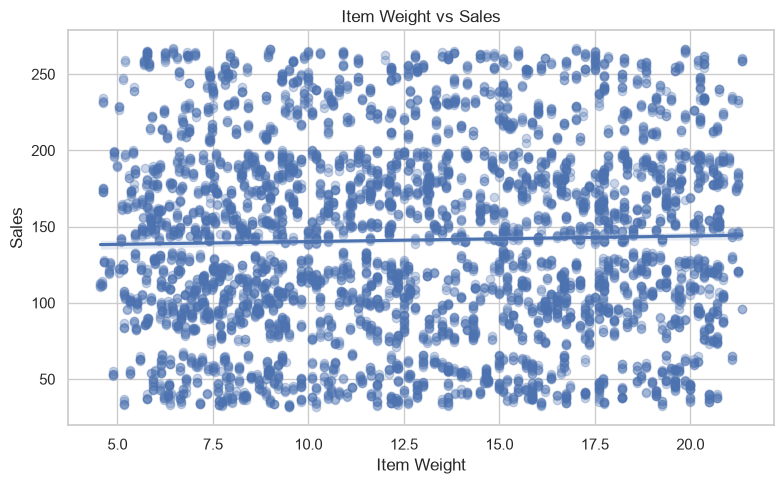

In [44]:
plt.figure(figsize=(8, 5))
sns.regplot(data=df, x="Item Weight", y="Sales",
            scatter_kws={"alpha": 0.3})
plt.title("Item Weight vs Sales")
plt.tight_layout()
plt.show()

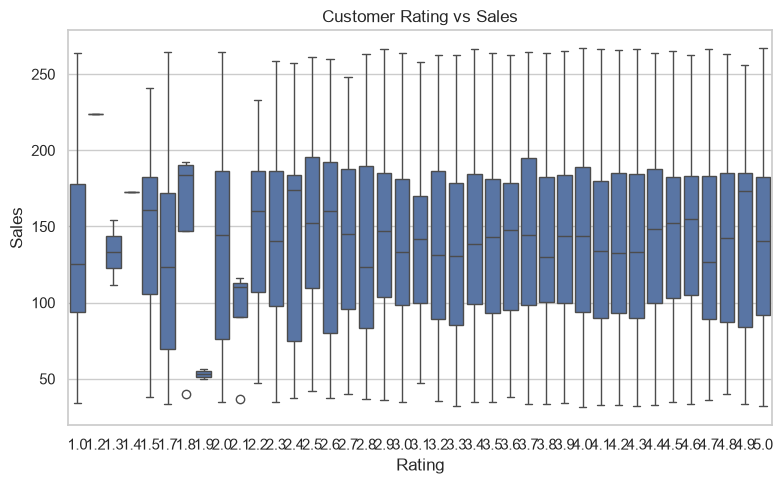

In [45]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Rating", y="Sales")
plt.title("Customer Rating vs Sales")
plt.tight_layout()
plt.show()

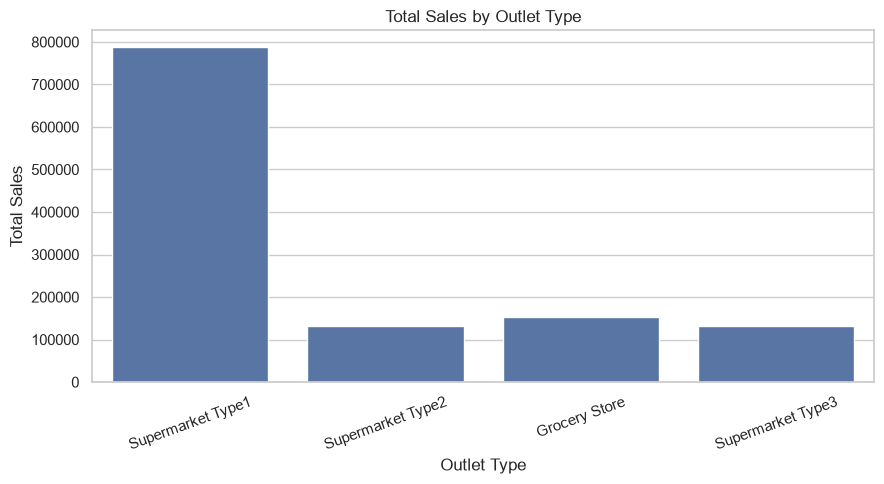

In [48]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x="Outlet Type",
    y="Sales",
    estimator="sum",
    errorbar=None
)

plt.title("Total Sales by Outlet Type")
plt.xlabel("Outlet Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

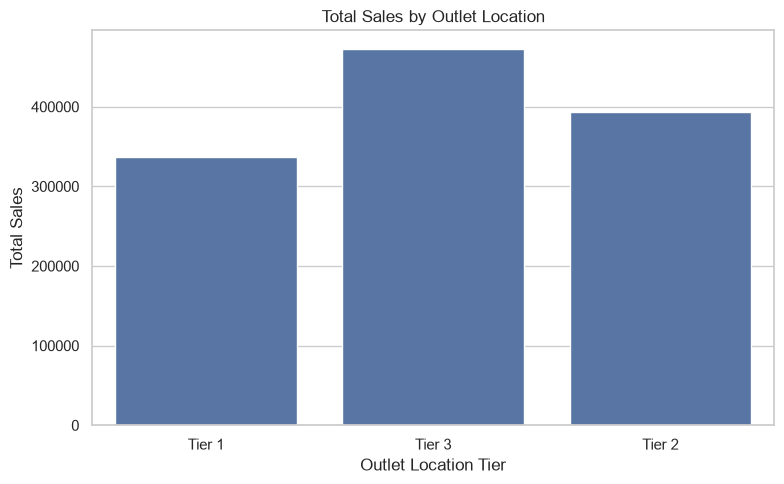

In [49]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df,
    x="Outlet Location Type",
    y="Sales",
    estimator="sum",
    errorbar=None
)

plt.title("Total Sales by Outlet Location")
plt.xlabel("Outlet Location Tier")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

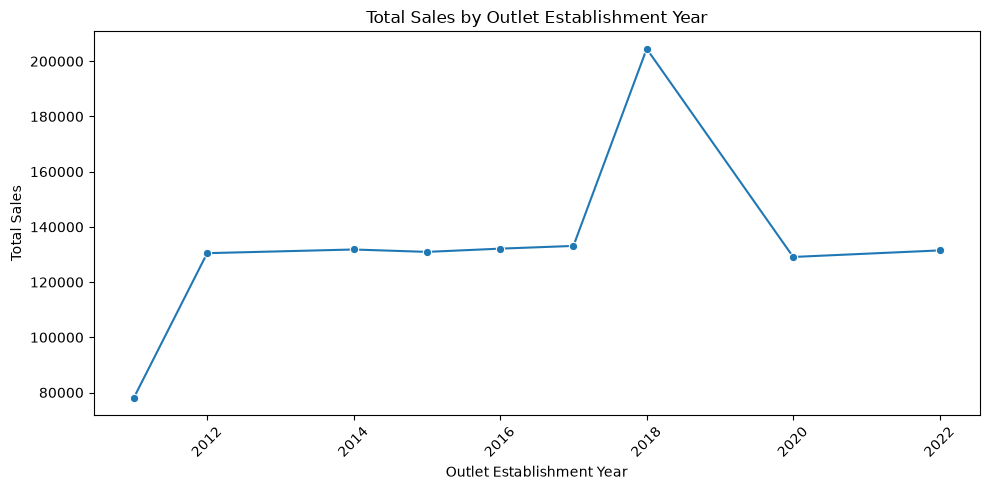

In [8]:
year_sales = (
    df.groupby("Outlet Establishment Year", as_index=False)["Sales"]
    .sum()
    .sort_values("Outlet Establishment Year")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=year_sales,
    x="Outlet Establishment Year",
    y="Sales",
    marker="o"
)

plt.title("Total Sales by Outlet Establishment Year")
plt.xlabel("Outlet Establishment Year")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [12]:
product_performance = (
    df.groupby("Item Type")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Total_Sales", ascending=False)
)
top_products = product_performance.head(5)
bottom_products = product_performance.tail(5)

print("Top 5 Product Categories:")
display(top_products.round(2))

print("Bottom 5 Product Categories:")
display(bottom_products.round(2))

Top 5 Product Categories:


,Total_Sales,Average_Sales,Average_Rating
Item Type,,,
Fruits and Vegetables,178124.08,144.58,3.96
Snack Foods,175433.92,146.19,3.95
Household,135976.53,149.42,4.00
Frozen Foods,118558.88,138.50,3.97
Dairy,101276.46,148.50,3.97


Bottom 5 Product Categories:


,Total_Sales,Average_Sales,Average_Rating
Item Type,,,
Hard Drinks,29334.68,137.08,3.91
Others,22451.89,132.85,3.95
Starchy Foods,21880.03,147.84,3.92
Breakfast,15596.70,141.79,3.93
Seafood,9077.87,141.84,3.96


In [13]:
outlet_performance = (
    df.groupby("Outlet Identifier")
    .agg(
        Outlet_Type=("Outlet Type", "first"),
        Location=("Outlet Location Type", "first"),
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Rating=("Rating", "mean"),
        Product_Records=("Sales", "count")
    )
    .sort_values("Total_Sales", ascending=False)
)
top_outlets = outlet_performance.head(5)
bottom_outlets = outlet_performance.tail(5)

print("Top 5 Outlets:")
display(top_outlets.round(2))

print("Bottom 5 Outlets:")
display(bottom_outlets.round(2))

Top 5 Outlets:


,Outlet_Type,Location,Total_Sales,Average_Sales,Average_Rating,Product_Records
Outlet Identifier,,,,,,
OUT035,Supermarket Type1,Tier 2,133103.91,143.12,3.94,930
OUT046,Supermarket Type1,Tier 1,132113.37,142.06,3.96,930
OUT013,Supermarket Type1,Tier 3,131809.02,141.43,3.95,932
OUT018,Supermarket Type2,Tier 3,131477.78,141.68,3.97,928
OUT045,Supermarket Type1,Tier 2,130942.78,140.95,3.96,929


Bottom 5 Outlets:


,Outlet_Type,Location,Total_Sales,Average_Sales,Average_Rating,Product_Records
Outlet Identifier,,,,,,
OUT027,Supermarket Type3,Tier 3,130714.67,139.80,3.95,935
OUT049,Supermarket Type1,Tier 1,130476.86,140.30,3.99,930
OUT017,Supermarket Type1,Tier 2,129103.96,139.42,3.98,926
OUT010,Grocery Store,Tier 3,78131.57,140.78,3.98,555
OUT019,Grocery Store,Tier 1,73807.58,139.79,4.00,528


In [18]:
category_sales = (
    df.groupby("Item Type")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

category_sales["Sales_Contribution_Percent"] = (
    category_sales["Sales"] / df["Sales"].sum()
) * 100

display(category_sales)

,Item Type,Sales,Sales_Contribution_Percent
0,Fruits and Vegetables,178124.0810,14.822903
1,Snack Foods,175433.9224,14.599037
2,Household,135976.5254,11.315521
3,Frozen Foods,118558.8814,9.866082
4,Dairy,101276.4616,8.427896
5,Canned,90706.7290,7.548317
6,Baking Goods,81894.7364,6.815012
7,Health and Hygiene,68025.8388,5.660888
8,Meat,59449.8638,4.947223
9,Soft Drinks,58514.1670,4.869357


In [19]:
outlet_sales = (
    df.groupby("Outlet Identifier")
    .agg(
        Outlet_Type=("Outlet Type", "first"),
        Location=("Outlet Location Type", "first"),
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Product_Count=("Sales", "count")
    )
    .sort_values("Total_Sales", ascending=False)
)

print("Top 10 Performing Outlets:")
display(outlet_sales.head(10))

Top 10 Performing Outlets:


,Outlet_Type,Location,Total_Sales,Average_Sales,Product_Count
Outlet Identifier,,,,,
OUT035,Supermarket Type1,Tier 2,133103.9070,143.122481,930
OUT046,Supermarket Type1,Tier 1,132113.3698,142.057387,930
OUT013,Supermarket Type1,Tier 3,131809.0156,141.425982,932
OUT018,Supermarket Type2,Tier 3,131477.7764,141.678638,928
OUT045,Supermarket Type1,Tier 2,130942.7802,140.950248,929
OUT027,Supermarket Type3,Tier 3,130714.6746,139.801791,935
OUT049,Supermarket Type1,Tier 1,130476.8598,140.297699,930
OUT017,Supermarket Type1,Tier 2,129103.9604,139.421124,926
OUT010,Grocery Store,Tier 3,78131.5666,140.777597,555


In [20]:
location_sales = (
    df.groupby("Outlet Location Type")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Number_of_Records=("Sales", "count")
    )
    .sort_values("Total_Sales", ascending=False)
)

print("Sales Performance by Location:")
display(location_sales)

Sales Performance by Location:


,Total_Sales,Average_Sales,Number_of_Records
Outlet Location Type,,,
Tier 3,472133.0332,140.935234,3350
Tier 2,393150.6476,141.167198,2785
Tier 1,336397.8120,140.870106,2388


In [22]:
product_performance = (
    df.groupby("Item Type")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Rating=("Rating", "mean")
    )
    .sort_values("Total_Sales")
)

print("10 Product Types with Lowest Total Sales:")
display(product_performance.head(10))

10 Product Types with Lowest Total Sales:


,Total_Sales,Average_Sales,Average_Rating
Item Type,,,
Seafood,9077.8700,141.841719,3.959375
Breakfast,15596.6966,141.788151,3.932727
Starchy Foods,21880.0274,147.838023,3.920270
Others,22451.8916,132.851430,3.954438
Hard Drinks,29334.6806,137.077947,3.907477
Breads,35379.1198,140.952669,3.881275
Soft Drinks,58514.1670,131.492510,3.920674
Meat,59449.8638,139.882032,4.023059
Health and Hygiene,68025.8388,130.818921,3.986154


In [23]:
outlet_performance = (
    df.groupby("Outlet Identifier")
    .agg(
        Outlet_Type=("Outlet Type", "first"),
        Location=("Outlet Location Type", "first"),
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Rating=("Rating", "mean"),
        Product_Records=("Sales", "count")
    )
    .sort_values("Total_Sales")
)

print("10 Outlets with Lowest Total Sales:")
display(outlet_performance.head(10))

10 Outlets with Lowest Total Sales:


,Outlet_Type,Location,Total_Sales,Average_Sales,Average_Rating,Product_Records
Outlet Identifier,,,,,,
OUT019,Grocery Store,Tier 1,73807.5824,139.787088,3.995076,528
OUT010,Grocery Store,Tier 3,78131.5666,140.777597,3.977117,555
OUT017,Supermarket Type1,Tier 2,129103.9604,139.421124,3.981641,926
OUT049,Supermarket Type1,Tier 1,130476.8598,140.297699,3.985484,930
OUT027,Supermarket Type3,Tier 3,130714.6746,139.801791,3.952941,935
OUT045,Supermarket Type1,Tier 2,130942.7802,140.950248,3.959957,929
OUT018,Supermarket Type2,Tier 3,131477.7764,141.678638,3.971228,928
OUT013,Supermarket Type1,Tier 3,131809.0156,141.425982,3.949571,932
OUT046,Supermarket Type1,Tier 1,132113.3698,142.057387,3.958387,930


In [24]:
location_performance = (
    df.groupby("Outlet Location Type")
    .agg(
        Total_Sales=("Sales", "sum"),
        Average_Sales=("Sales", "mean"),
        Number_of_Records=("Sales", "count")
    )
    .sort_values("Average_Sales")
)

print("Location Performance:")
display(location_performance)

Location Performance:


,Total_Sales,Average_Sales,Number_of_Records
Outlet Location Type,,,
Tier 1,336397.8120,140.870106,2388
Tier 3,472133.0332,140.935234,3350
Tier 2,393150.6476,141.167198,2785


In [25]:
print("========== BUSINESS IMPROVEMENT SUGGESTIONS ==========")

# Products needing attention
low_sales_products = product_performance.nsmallest(5, "Total_Sales")

print("\n1. PRODUCTS NEEDING IMPROVEMENT")
display(low_sales_products)

print("Suggestion:")
print("- Review product pricing, demand, stock availability, and shelf placement.")
print("- Promote products with low sales but good customer ratings.")
print("- Review customer feedback for products with low ratings.")

# Outlets needing attention
low_sales_outlets = outlet_performance.nsmallest(5, "Average_Sales")

print("\n2. OUTLETS NEEDING IMPROVEMENT")
display(low_sales_outlets)

print("Suggestion:")
print("- Check stock availability and product assortment.")
print("- Compare performance with similar outlets.")
print("- Investigate local customer demand and promotional effectiveness.")

# Locations needing attention
low_sales_locations = location_performance.nsmallest(3, "Average_Sales")

print("\n3. LOCATIONS NEEDING IMPROVEMENT")
display(low_sales_locations)

print("Suggestion:")
print("- Adapt the product mix to local customer preferences.")
print("- Test targeted offers and bundles.")
print("- Review outlet accessibility, availability, and local competition.")

# Best-selling product types
top_products = product_performance.nlargest(5, "Total_Sales")

print("\n4. TOP-PERFORMING PRODUCT TYPES")
display(top_products)

print("Suggestion:")
print("- Maintain reliable stock of popular product types.")
print("- Test complementary-product bundles.")
print("- Monitor stockouts so strong demand is not lost.")

print("\n5. OVERALL BUSINESS IMPROVEMENTS")
print("- Track sales, average sales, and ratings regularly.")
print("- Test discounts on selected products before expanding them.")
print("- Measure promotional results against a baseline.")
print("- Monitor inventory to reduce stockouts and excess stock.")

========== BUSINESS IMPROVEMENT SUGGESTIONS ==========

1. PRODUCTS NEEDING IMPROVEMENT


,Total_Sales,Average_Sales,Average_Rating
Item Type,,,
Seafood,9077.8700,141.841719,3.959375
Breakfast,15596.6966,141.788151,3.932727
Starchy Foods,21880.0274,147.838023,3.920270
Others,22451.8916,132.851430,3.954438
Hard Drinks,29334.6806,137.077947,3.907477


Suggestion:
- Review product pricing, demand, stock availability, and shelf placement.
- Promote products with low sales but good customer ratings.
- Review customer feedback for products with low ratings.

2. OUTLETS NEEDING IMPROVEMENT


,Outlet_Type,Location,Total_Sales,Average_Sales,Average_Rating,Product_Records
Outlet Identifier,,,,,,
OUT017,Supermarket Type1,Tier 2,129103.9604,139.421124,3.981641,926
OUT019,Grocery Store,Tier 1,73807.5824,139.787088,3.995076,528
OUT027,Supermarket Type3,Tier 3,130714.6746,139.801791,3.952941,935
OUT049,Supermarket Type1,Tier 1,130476.8598,140.297699,3.985484,930
OUT010,Grocery Store,Tier 3,78131.5666,140.777597,3.977117,555


Suggestion:
- Check stock availability and product assortment.
- Compare performance with similar outlets.
- Investigate local customer demand and promotional effectiveness.

3. LOCATIONS NEEDING IMPROVEMENT


,Total_Sales,Average_Sales,Number_of_Records
Outlet Location Type,,,
Tier 1,336397.8120,140.870106,2388
Tier 3,472133.0332,140.935234,3350
Tier 2,393150.6476,141.167198,2785


Suggestion:
- Adapt the product mix to local customer preferences.
- Test targeted offers and bundles.
- Review outlet accessibility, availability, and local competition.

4. TOP-PERFORMING PRODUCT TYPES


,Total_Sales,Average_Sales,Average_Rating
Item Type,,,
Fruits and Vegetables,178124.0810,144.581235,3.956169
Snack Foods,175433.9224,146.194935,3.948917
Household,135976.5254,149.424753,3.998681
Frozen Foods,118558.8814,138.503366,3.971145
Dairy,101276.4616,148.499211,3.965836


Suggestion:
- Maintain reliable stock of popular product types.
- Test complementary-product bundles.
- Monitor stockouts so strong demand is not lost.

5. OVERALL BUSINESS IMPROVEMENTS
- Track sales, average sales, and ratings regularly.
- Test discounts on selected products before expanding them.
- Measure promotional results against a baseline.
- Monitor inventory to reduce stockouts and excess stock.
